# Experiment 2: The eight queens problem

Generate-and-test over permutations against backtracking with pruning, for
n = 4 to 10. Board encoding: board[c] = row of the queen in column c.

In [1]:
import json, platform, subprocess, time
from itertools import permutations
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'font.size': 10})
cpu = subprocess.run(['sysctl', '-n', 'machdep.cpu.brand_string'], capture_output=True,
                     text=True).stdout.strip() or platform.processor()
print('Python', platform.python_version(), '|', platform.platform(), '|', cpu)

Python 3.12.16 | macOS-27.0-arm64-arm-64bit | Apple M5


## Generate and test
Permutations already put one queen in every row and column, so only the
diagonal test |r_i - r_j| = |i - j| is left.

In [2]:
def conflicts(board):
    """Number of attacking pairs on a board given as one row index per column."""
    n, bad = len(board), 0
    for i in range(n):
        for j in range(i + 1, n):
            if board[i] == board[j] or abs(board[i] - board[j]) == abs(i - j):
                bad += 1
    return bad

def generate_and_test(n):
    return [p for p in permutations(range(n)) if conflicts(p) == 0]

t0 = time.perf_counter()
gt8 = generate_and_test(8)
print(len(gt8), 'solutions by generate-and-test in', round(time.perf_counter() - t0, 4), 's')

92 solutions by generate-and-test in 0.0521 s


## Backtracking with pruning

In [3]:
def is_safe(board, col, row):
    """Only columns 0..col-1 hold queens yet, so only those can attack (row, col)."""
    for c in range(col):
        if board[c] == row or abs(board[c] - row) == abs(c - col):
            return False
    return True

def solve(n=8):
    sols, nodes = [], [0]
    def place(board, col):
        if col == n:
            sols.append(tuple(board)); return
        for row in range(n):
            nodes[0] += 1
            if is_safe(board, col, row):
                board[col] = row          # place
                place(board, col + 1)
                board[col] = -1           # undo before trying the next row
    place([-1] * n, 0)
    return sols, nodes[0]

sols, nodes = solve(8)
print(len(sols), 'solutions,', nodes, 'nodes visited; first solution', sols[0])
assert sorted(sols) == sorted(gt8), 'the two methods disagree'

92 solutions, 15720 nodes visited; first solution (0, 4, 7, 5, 2, 6, 1, 3)


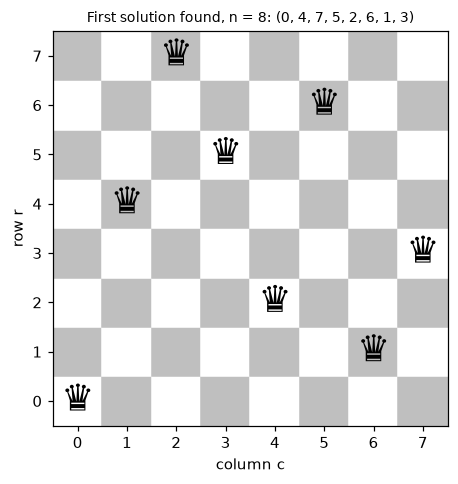

In [4]:
def draw_board(solution, fname):
    n = len(solution)
    fig, ax = plt.subplots(figsize=(4.5, 4.5))
    for row in range(n):
        for col in range(n):
            ax.add_patch(plt.Rectangle((col, row), 1, 1,
                         color='white' if (row + col) % 2 == 0 else '0.75'))
    for col, row in enumerate(solution):
        ax.text(col + 0.5, row + 0.5, '♛', fontsize=24, ha='center', va='center')
    ax.set_xlim(0, n); ax.set_ylim(0, n)
    ax.set_xticks([i + 0.5 for i in range(n)]); ax.set_xticklabels(range(n))
    ax.set_yticks([i + 0.5 for i in range(n)]); ax.set_yticklabels(range(n))
    ax.set_xlabel('column c'); ax.set_ylabel('row r')
    ax.set_aspect('equal'); ax.set_title(f'First solution found, n = {n}: {solution}', fontsize=9)
    fig.tight_layout(); fig.savefig(fname)

draw_board(sols[0], 'figs/fig2_1_first_solution.png')

## Scaling from n = 4 to 10

In [5]:
rows = []
print(f"{'n':>3} {'solutions':>10} {'nodes':>10} {'backtrack':>11} {'generate':>11}")
for n in range(4, 11):
    t0 = time.perf_counter(); s, nd = solve(n); tb = time.perf_counter() - t0
    t0 = time.perf_counter(); g = generate_and_test(n); tg = time.perf_counter() - t0
    assert len(s) == len(g)
    rows.append(dict(n=n, solutions=len(s), gt_solutions=len(g), nodes=nd, t_bt=tb, t_gt=tg))
    print(f'{n:>3} {len(s):>10} {nd:>10} {tb:>10.4f}s {tg:>10.4f}s')

  n  solutions      nodes   backtrack    generate
  4          2         60     0.0000s     0.0000s
  5         10        220     0.0000s     0.0001s
  6          4        894     0.0001s     0.0005s
  7         40       3584     0.0004s     0.0050s


  8         92      15720     0.0022s     0.0515s


  9        352      72378     0.0114s     0.5727s


 10        724     348150     0.0571s     7.1897s


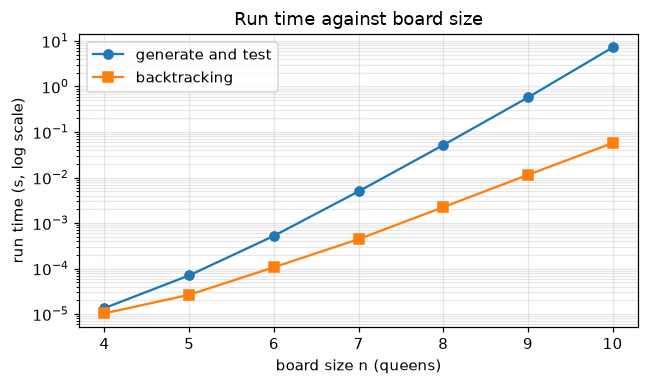

In [6]:
ns = [r['n'] for r in rows]
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.semilogy(ns, [r['t_gt'] for r in rows], 'o-', label='generate and test')
ax.semilogy(ns, [r['t_bt'] for r in rows], 's-', label='backtracking')
ax.set_xlabel('board size n (queens)'); ax.set_ylabel('run time (s, log scale)')
ax.set_title('Run time against board size'); ax.grid(True, which='both', alpha=0.3); ax.legend()
fig.tight_layout(); fig.savefig('figs/fig2_2_runtime.png')

In [7]:
# Distinct solutions under the 8 symmetries of the square (n = 8)
def symmetries(b):
    n = len(b); pts = [(c, r) for c, r in enumerate(b)]
    out = []
    for k in range(4):
        for flip in (False, True):
            q = pts
            for _ in range(k):
                q = [(r, n - 1 - c) for c, r in q]          # rotate 90°
            if flip:
                q = [(n - 1 - c, r) for c, r in q]          # mirror
            nb = [0] * n
            for c, r in q: nb[c] = r
            out.append(tuple(nb))
    return out
fundamental = {min(symmetries(s)) for s in sols}
print('fundamental solutions for n = 8:', len(fundamental))

with open('obs.json', 'w') as fh:
    json.dump(dict(cpu=cpu, python=platform.python_version(), rows=rows,
                   first_solution=sols[0], fundamental=len(fundamental)), fh, indent=1)

fundamental solutions for n = 8: 12
